# Lab 2: Simple Quantum Gates

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yamaalluddin9470-cmyk/Report-Lab104/blob/main/Lab2/lab-2-quantum-gates.ipynb)

**Course:** SCI-104 – Mathematical Foundations and Quantum Mechanics Essentials<br>
**Student:** Yamalluddin Chahama (6930614038), AISE<br>
**Instructor:** Komsan Kanjanasit

Lab sheet: [komsan-k/quantum-computation – lab-2-quantum-gates](https://github.com/komsan-k/quantum-computation/tree/main/lab/lab-2-quantum-gates)

In Colab: **Runtime → Run all**. Every figure is also saved to `images/` (the PNGs used in the report).

## Task 1 — Setup

In [1]:
%pip install -q qiskit qiskit-aer pylatexenc

In [2]:
import os, sys
import numpy as np
from math import pi
import matplotlib.pyplot as plt
import qiskit, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator, Pauli, partial_trace, average_gate_fidelity
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_aer import Aer

print("Python", sys.version.split()[0], "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

os.makedirs("images", exist_ok=True)
backend = Aer.get_backend("aer_simulator")
SHOTS, SEED = 1024, 42          # fixed seed -> reproducible counts

def show(fig, name):
    """Display a figure and save it as images/<name>.png."""
    fig.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    display(fig)
    plt.close(fig)

def bloch_plot(sv, title):
    """Bloch sphere(s) seen from a lower, more upright angle than Qiskit's default (elev 30° -> 20°)."""
    fig = plot_bloch_multivector(sv, title=title)
    for ax in fig.axes:
        ax.view_init(elev=20, azim=-60)
        ax.set_title(ax.get_title(), pad=45, fontsize=ax.title.get_fontsize())  # keep "qubit k" above the |0> label
    return fig

def hist_plot(counts, title):
    """Histogram with upright x labels (Qiskit rotates them 70° by default)."""
    fig = plot_histogram(counts, title=title)
    fig.axes[0].tick_params(axis="x", labelrotation=0)
    return fig

def bloch(sv):
    """Bloch vector (x, y, z) = (<X>, <Y>, <Z>) of a single-qubit state."""
    return tuple(round(float(sv.expectation_value(Pauli(p)).real), 4) + 0.0 for p in "XYZ")

def pdict(sv):
    """Non-zero measurement probabilities as {bitstring: p}."""
    return {str(k): round(float(v), 4) for k, v in sv.probabilities_dict().items()}

def bloch_of(rho):
    """Bloch vector of a (possibly mixed) single-qubit density matrix."""
    return tuple(round(float(rho.expectation_value(Pauli(p)).real), 4) + 0.0 for p in "XYZ")

def describe(sv, label):
    line = f"{label:<10} amplitudes={np.round(sv.data, 4)}  P={np.round(sv.probabilities(), 4)}"
    if sv.num_qubits == 1:
        line += f"  Bloch={bloch(sv)}"
    print(line)

def counts(qc):
    return backend.run(qc, shots=SHOTS, seed_simulator=SEED).result().get_counts()

Python 3.14.6 | qiskit 2.6.0 | qiskit-aer 0.17.2


## Task 2 — Pauli Gates

First check that every gate used in this lab is **unitary** ($U^\dagger U = I$), then apply X, Y, Z to $|0\rangle$ and to $|+\rangle$.

In [3]:
single = {"X": "x", "Y": "y", "Z": "z", "H": "h", "S": "s", "T": "t"}
for name, g in single.items():
    qc = QuantumCircuit(1); getattr(qc, g)(0)
    U = Operator(qc).data
    print(f"{name} =\n{np.round(U, 4)}\n  unitary (U†U = I): {np.allclose(U.conj().T @ U, np.eye(2))}\n")

X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
  unitary (U†U = I): True

Y =
[[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]]
  unitary (U†U = I): True

Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
  unitary (U†U = I): True

H =
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]
  unitary (U†U = I): True

S =
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]
  unitary (U†U = I): True

T =
[[1.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.7071+0.7071j]]
  unitary (U†U = I): True



Pauli gates on |0>
X|0>       amplitudes=[0.+0.j 1.+0.j]  P=[0. 1.]  Bloch=(0.0, 0.0, -1.0)


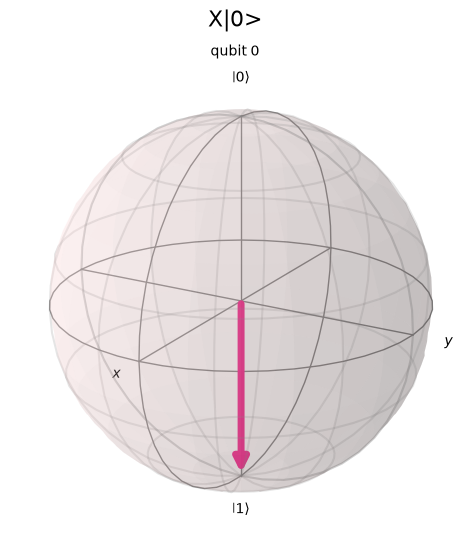

Y|0>       amplitudes=[0.+0.j 0.+1.j]  P=[0. 1.]  Bloch=(0.0, 0.0, -1.0)


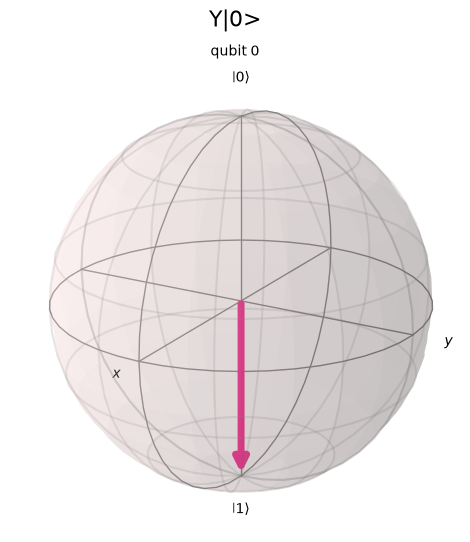

Z|0>       amplitudes=[1.+0.j 0.+0.j]  P=[1. 0.]  Bloch=(0.0, 0.0, 1.0)


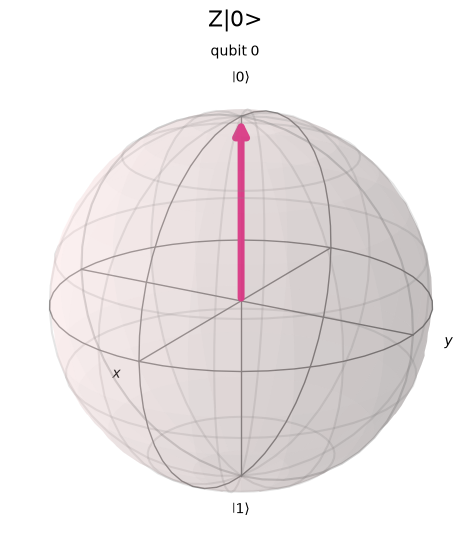

In [4]:
print("Pauli gates on |0>")
for g in "xyz":
    qc = QuantumCircuit(1); getattr(qc, g)(0)
    sv = Statevector.from_instruction(qc)
    describe(sv, f"{g.upper()}|0>")
    show(bloch_plot(sv, title=f"{g.upper()}|0>"), f"task2-{g}-on-0")

Pauli gates on |+> (Z has no visible effect on |0>, so test on |+> too)
X|+>       amplitudes=[0.7071+0.j 0.7071+0.j]  P=[0.5 0.5]  Bloch=(1.0, 0.0, 0.0)


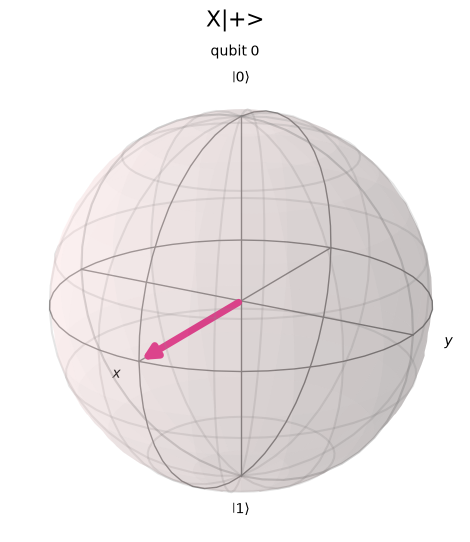

Y|+>       amplitudes=[0.-0.7071j 0.+0.7071j]  P=[0.5 0.5]  Bloch=(-1.0, 0.0, 0.0)


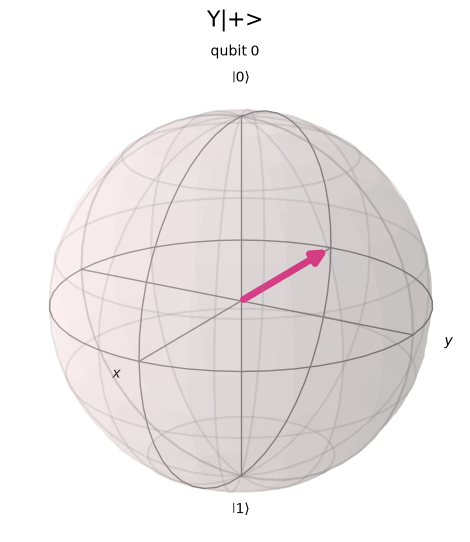

Z|+>       amplitudes=[ 0.7071+0.j -0.7071+0.j]  P=[0.5 0.5]  Bloch=(-1.0, 0.0, 0.0)


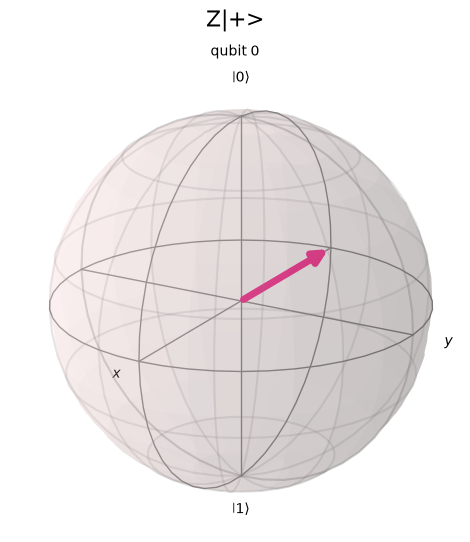

In [5]:
print("Pauli gates on |+> (Z has no visible effect on |0>, so test on |+> too)")
for g in "xyz":
    qc = QuantumCircuit(1); qc.h(0); getattr(qc, g)(0)
    sv = Statevector.from_instruction(qc)
    describe(sv, f"{g.upper()}|+>")
    show(bloch_plot(sv, title=f"{g.upper()}|+>"), f"task2-{g}-on-plus")

## Task 3 — Hadamard Gate and Measurement

H|0>       amplitudes=[0.7071+0.j 0.7071+0.j]  P=[0.5 0.5]  Bloch=(1.0, 0.0, 0.0)


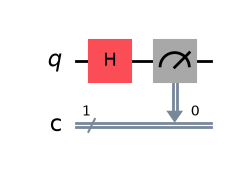

counts: {'0': 526, '1': 498} | P(0) ≈ 0.513671875 | P(1) ≈ 0.486328125


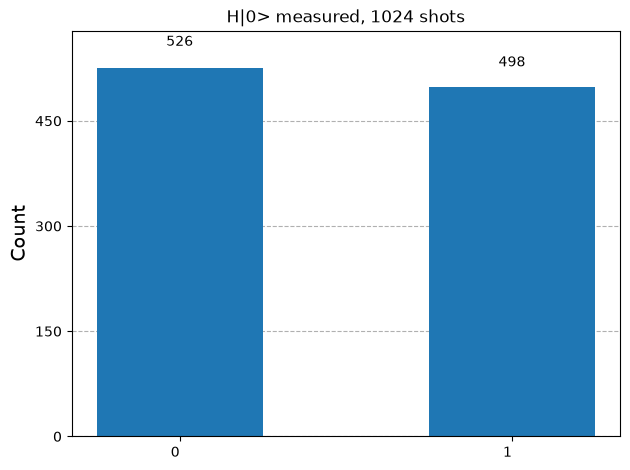

In [6]:
qc = QuantumCircuit(1, 1)
qc.h(0)
describe(Statevector.from_instruction(qc.remove_final_measurements(inplace=False)), "H|0>")
qc.measure(0, 0)
display(qc.draw("mpl"))

c = counts(qc)
print("counts:", c, "| P(0) ≈", c.get("0", 0) / SHOTS, "| P(1) ≈", c.get("1", 0) / SHOTS)
show(hist_plot(c, title="H|0> measured, 1024 shots"), "task3-h-histogram")

## Task 4 — Phase and Rotation Gates

The lab sheet applies `s` (or `t`) **then** `h`. Because S and T only change the phase of $|1\rangle$, they do nothing to $|0\rangle$, so the gate order is also swapped to see their effect.

S then H   amplitudes=[0.7071+0.j 0.7071+0.j]  P=[0.5 0.5]  Bloch=(1.0, 0.0, 0.0)


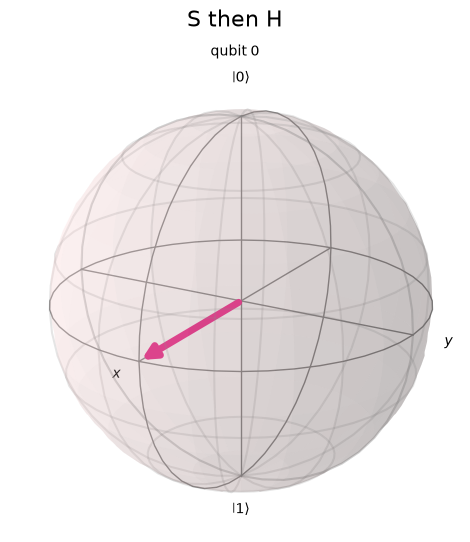

T then H   amplitudes=[0.7071+0.j 0.7071+0.j]  P=[0.5 0.5]  Bloch=(1.0, 0.0, 0.0)


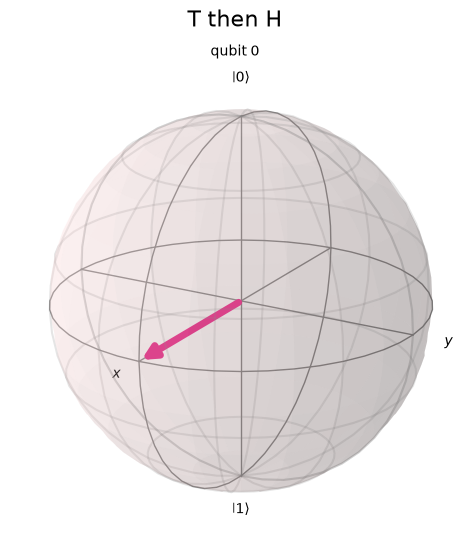

H then S   amplitudes=[0.7071+0.j     0.    +0.7071j]  P=[0.5 0.5]  Bloch=(0.0, 1.0, 0.0)


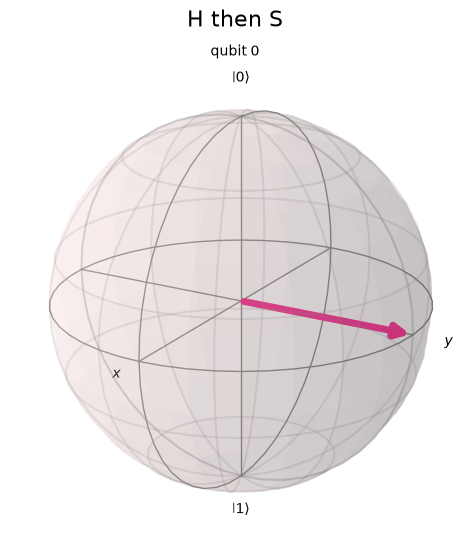

H then T   amplitudes=[0.7071+0.j  0.5   +0.5j]  P=[0.5 0.5]  Bloch=(0.7071, 0.7071, 0.0)


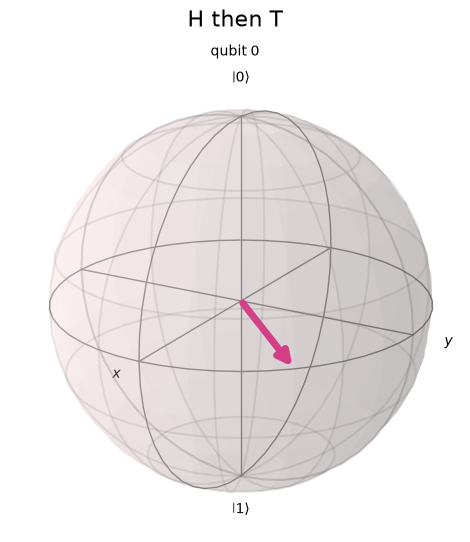

In [7]:
cases = {
    "S then H": lambda q: (q.s(0), q.h(0)),
    "T then H": lambda q: (q.t(0), q.h(0)),
    "H then S": lambda q: (q.h(0), q.s(0)),
    "H then T": lambda q: (q.h(0), q.t(0)),
}
for label, build in cases.items():
    qc = QuantumCircuit(1); build(qc)
    sv = Statevector.from_instruction(qc)
    describe(sv, label)
    show(bloch_plot(sv, title=label), "task4-" + label.lower().replace(" ", "-"))

Ry(pi/4)   amplitudes=[0.9239+0.j 0.3827+0.j]  P=[0.8536 0.1464]  Bloch=(0.7071, 0.0, 0.7071)
hand calculation: cos(pi/8) = 0.9239  sin(pi/8) = 0.3827


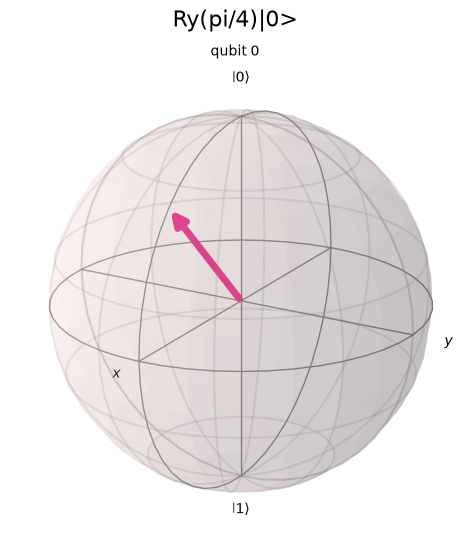

In [8]:
qc = QuantumCircuit(1)
qc.ry(pi/4, 0)
sv = Statevector.from_instruction(qc)
describe(sv, "Ry(pi/4)")
print("hand calculation: cos(pi/8) =", round(np.cos(pi/8), 4), " sin(pi/8) =", round(np.sin(pi/8), 4))
show(bloch_plot(sv, title="Ry(pi/4)|0>"), "task4-ry-pi4")

## Task 5 — Two-Qubit Gates (Bell State)

Bell state amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]  P = {'00': 0.5, '11': 0.5}


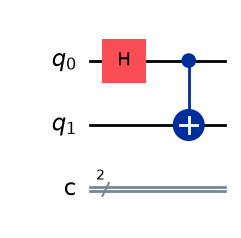

counts: {'11': 503, '00': 521}


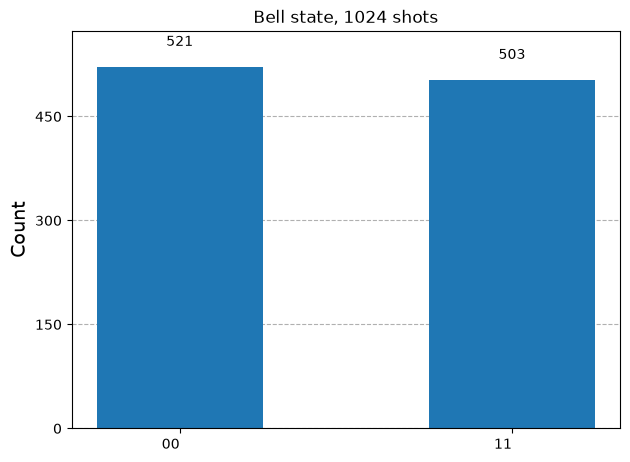

In [9]:
bell = QuantumCircuit(2, 2)
bell.h(0)
bell.cx(0, 1)
sv_bell = Statevector.from_instruction(bell)      # state before measurement
print("Bell state amplitudes:", np.round(sv_bell.data, 4), " P =", pdict(sv_bell))
show(bell.draw("mpl"), "task5-bell-circuit")

bell.measure([0, 1], [0, 1])
c = counts(bell)
print("counts:", c)
show(hist_plot(c, title="Bell state, 1024 shots"), "task5-bell-histogram")

qubit 0: rho =
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
  Bloch = (0.0, 0.0, 0.0)  purity = 0.5000
qubit 1: rho =
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
  Bloch = (0.0, 0.0, 0.0)  purity = 0.5000


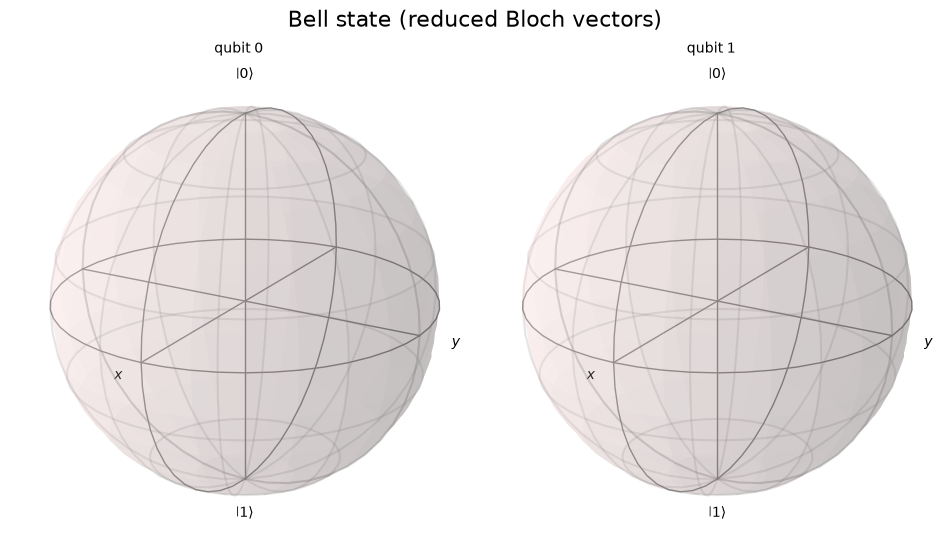

In [10]:
# Each qubit alone: reduced density matrix and its purity Tr(rho^2)
for k in range(2):
    rho = partial_trace(sv_bell, [1 - k])
    print(f"qubit {k}: rho =\n{np.round(rho.data, 4)}\n  Bloch = {bloch_of(rho)}  purity = {rho.purity().real:.4f}")
show(bloch_plot(sv_bell, title="Bell state (reduced Bloch vectors)"), "task5-bell-bloch")

## Exercise 1 — X-Y-Z Rotation: $R_x(\pi/2)$, $R_y(\pi/2)$, $R_z(\pi/2)$ on $|0\rangle$

RX(pi/2)   amplitudes=[0.7071+0.j     0.    -0.7071j]  P=[0.5 0.5]  Bloch=(0.0, -1.0, 0.0)


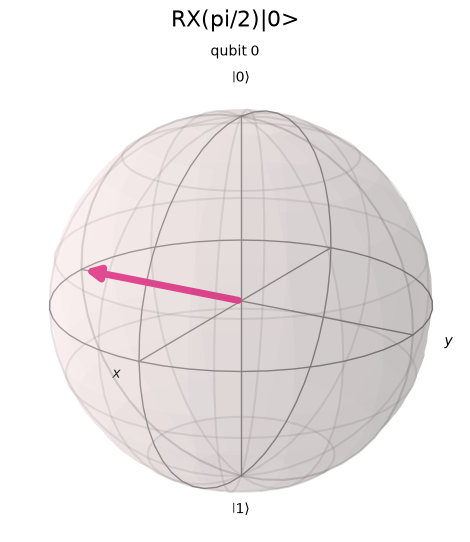

RY(pi/2)   amplitudes=[0.7071+0.j 0.7071+0.j]  P=[0.5 0.5]  Bloch=(1.0, 0.0, 0.0)


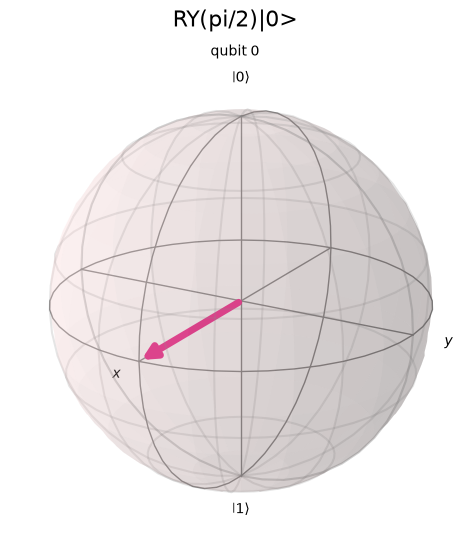

RZ(pi/2)   amplitudes=[0.7071-0.7071j 0.    +0.j    ]  P=[1. 0.]  Bloch=(0.0, 0.0, 1.0)


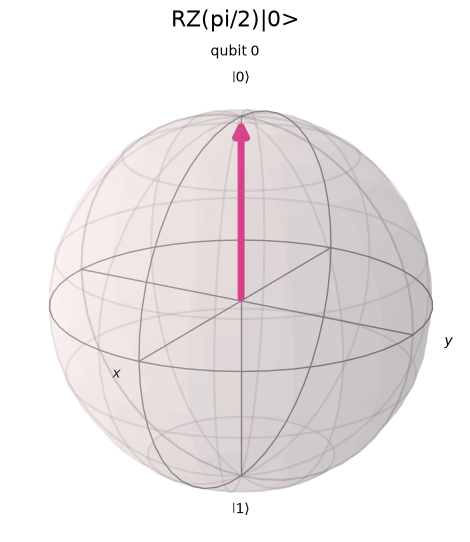

In [11]:
for g in ["rx", "ry", "rz"]:
    qc = QuantumCircuit(1); getattr(qc, g)(pi/2, 0)
    sv = Statevector.from_instruction(qc)
    describe(sv, f"{g.upper()}(pi/2)")
    show(bloch_plot(sv, title=f"{g.upper()}(pi/2)|0>"), f"ex1-{g}-pi2")

## Exercise 2 — H-S Combination

As an operator, $HS|0\rangle = H(S|0\rangle)$: **S acts first**. In a Qiskit circuit that is `s` then `h`. Compare with $SH|0\rangle$.

circuit s→h equals matrix H@S: True
HS == SH ? False 

HS|0>      amplitudes=[0.7071+0.j 0.7071+0.j]  P=[0.5 0.5]  Bloch=(1.0, 0.0, 0.0)


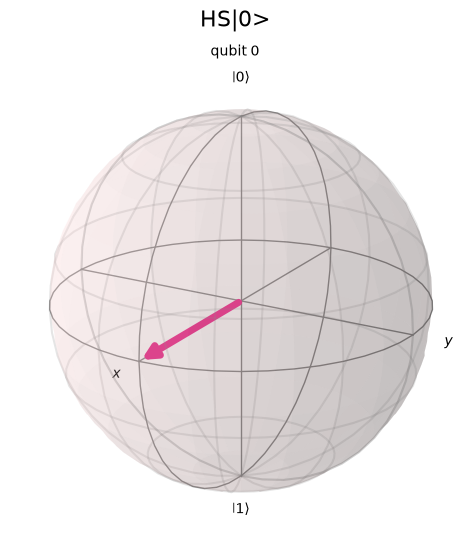

SH|0>      amplitudes=[0.7071+0.j     0.    +0.7071j]  P=[0.5 0.5]  Bloch=(0.0, 1.0, 0.0)


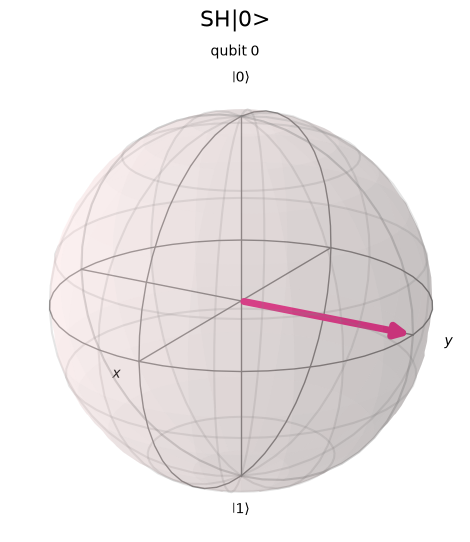

In [12]:
qc_HS = QuantumCircuit(1); qc_HS.s(0); qc_HS.h(0)     # matrix H·S
qc_SH = QuantumCircuit(1); qc_SH.h(0); qc_SH.s(0)     # matrix S·H

H = Operator.from_label("H").data
S = Operator.from_label("S").data
print("circuit s→h equals matrix H@S:", np.allclose(Operator(qc_HS).data, H @ S))
print("HS == SH ?", np.allclose(H @ S, S @ H), "\n")

for label, qc in [("HS|0>", qc_HS), ("SH|0>", qc_SH)]:
    sv = Statevector.from_instruction(qc)
    describe(sv, label)
    show(bloch_plot(sv, title=label), "ex2-" + label[:2].lower())

## Exercise 3 — SWAP Gate

Qiskit labels basis states as $|q_1 q_0\rangle$ (qubit 0 is the **rightmost** bit). So `x(0)` prepares $|01\rangle$.

before SWAP: {'01': 1.0}
after  SWAP: {'10': 1.0}


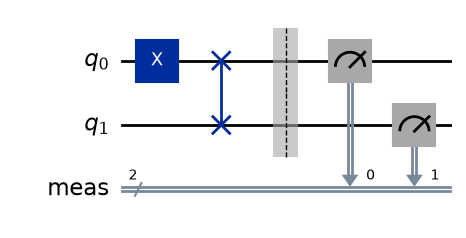

counts: {'10': 1024}


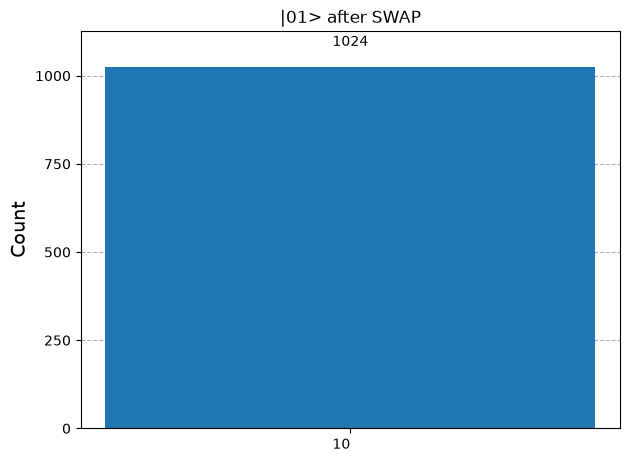

In [13]:
qc = QuantumCircuit(2)
qc.x(0)
before = Statevector.from_instruction(qc)
qc.swap(0, 1)
after = Statevector.from_instruction(qc)
print("before SWAP:", pdict(before))
print("after  SWAP:", pdict(after))

qc.measure_all()
show(qc.draw("mpl"), "ex3-swap-circuit")
c = counts(qc)
print("counts:", c)
show(hist_plot(c, title="|01> after SWAP"), "ex3-swap-histogram")

## Exercise 4 — CZ Gate

Control = qubit 0 in $|+\rangle$. Three cases for the target (qubit 1): $|0\rangle$, $|1\rangle$, $|+\rangle$.

--- target |0> ---
before: [0.7071+0.j 0.7071+0.j 0.    +0.j 0.    +0.j]  P = {'00': 0.5, '01': 0.5}
after : [0.7071+0.j 0.7071+0.j 0.    +0.j 0.    +0.j]  P = {'00': 0.5, '01': 0.5}
control qubit after CZ: Bloch = (1.0, 0.0, 0.0)  purity = 1.0000

--- target |1> ---
before: [0.    +0.j 0.    +0.j 0.7071+0.j 0.7071+0.j]  P = {'10': 0.5, '11': 0.5}
after : [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j]  P = {'10': 0.5, '11': 0.5}
control qubit after CZ: Bloch = (-1.0, 0.0, 0.0)  purity = 1.0000

--- target |+> ---
before: [0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]  P = {'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}
after : [ 0.5+0.j  0.5+0.j  0.5+0.j -0.5+0.j]  P = {'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}
control qubit after CZ: Bloch = (0.0, 0.0, 0.0)  purity = 0.5000



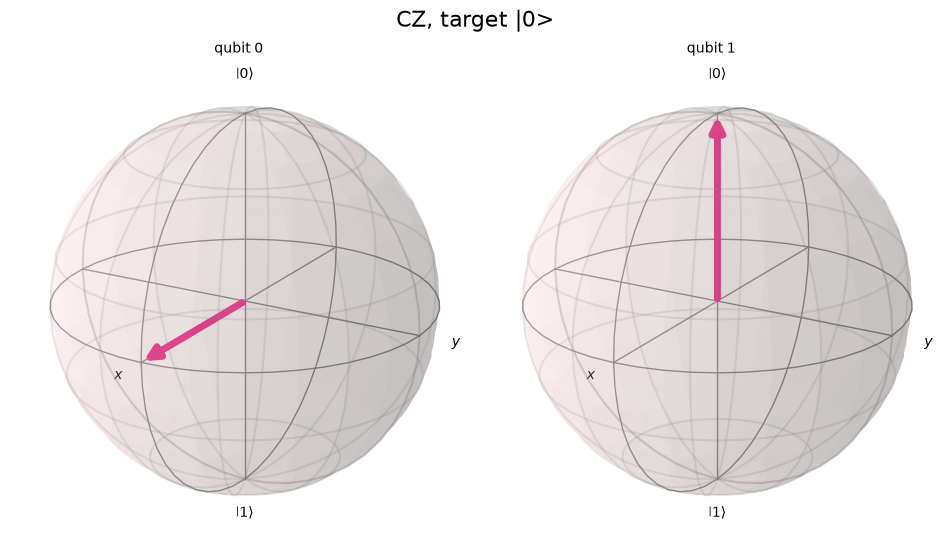

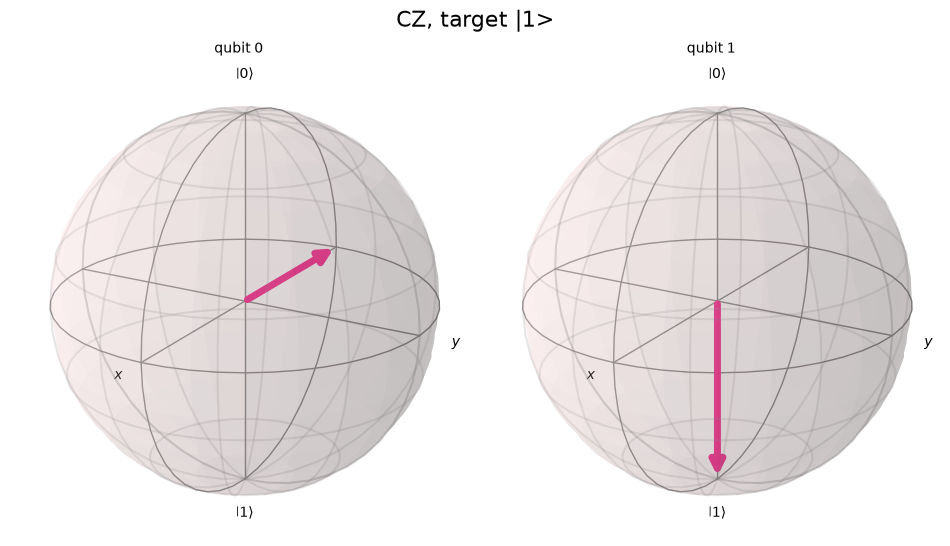

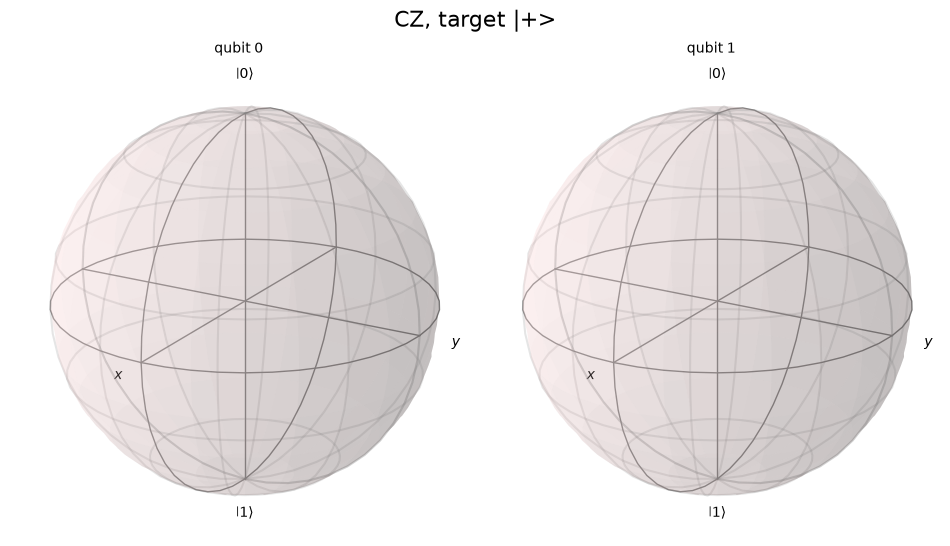

CZ is symmetric (cz(0,1) == cz(1,0)): True


In [14]:
def cz_case(prep_target, label):
    qc = QuantumCircuit(2)
    qc.h(0)              # control in |+>
    prep_target(qc)      # target state
    before = Statevector.from_instruction(qc)
    qc.cz(0, 1)
    after = Statevector.from_instruction(qc)
    print(f"--- target {label} ---")
    print("before:", np.round(before.data, 4), " P =", pdict(before))
    print("after :", np.round(after.data, 4),  " P =", pdict(after))
    ctrl = partial_trace(after, [1])
    print(f"control qubit after CZ: Bloch = {bloch_of(ctrl)}  purity = {ctrl.purity().real:.4f}\n")
    return after

a = cz_case(lambda q: None,         "|0>")
b = cz_case(lambda q: q.x(1),       "|1>")
c_ = cz_case(lambda q: q.h(1),      "|+>")

show(bloch_plot(a,  title="CZ, target |0>"), "ex4-cz-target0")
show(bloch_plot(b,  title="CZ, target |1>"), "ex4-cz-target1")
show(bloch_plot(c_, title="CZ, target |+>"), "ex4-cz-targetplus")

qa = QuantumCircuit(2); qa.cz(0, 1)
qb = QuantumCircuit(2); qb.cz(1, 0)
print("CZ is symmetric (cz(0,1) == cz(1,0)):", Operator(qa).equiv(Operator(qb)))

## Exercise 5 — Universality Challenge: {H, T, CNOT}

**(a) Exact constructions.** `Operator.equiv` compares up to a global phase; `exact` checks equality without any phase.

In [15]:
def from_ops(n, ops):
    qc = QuantumCircuit(n)
    for name, *qubits in ops:
        getattr(qc, name)(*qubits)
    return qc

def ref(n, name, *qubits):
    qc = QuantumCircuit(n); getattr(qc, name)(*qubits); return qc

T = [("t", 0)]
constructions = [
    ("S = T·T",              ref(1, "s", 0),        from_ops(1, T * 2)),
    ("Z = T^4",              ref(1, "z", 0),        from_ops(1, T * 4)),
    ("X = H·T^4·H",          ref(1, "x", 0),        from_ops(1, [("h", 0)] + T * 4 + [("h", 0)])),
    ("Y = S·X·S† = T²·H·T⁴·H·T⁶", ref(1, "y", 0),   from_ops(1, T * 6 + [("h", 0)] + T * 4 + [("h", 0)] + T * 2)),
    ("CZ = (H on target)·CNOT·(H on target)", ref(2, "cz", 0, 1), from_ops(2, [("h", 1), ("cx", 0, 1), ("h", 1)])),
    ("SWAP = 3 CNOTs",       ref(2, "swap", 0, 1),  from_ops(2, [("cx", 0, 1), ("cx", 1, 0), ("cx", 0, 1)])),
]
for label, target, built in constructions:
    U, V = Operator(target), Operator(built)
    print(f"{label:<42} equiv: {U.equiv(V)}   exact: {np.allclose(U.data, V.data)}   gates: {dict(built.count_ops())}")

S = T·T                                    equiv: True   exact: True   gates: {'t': 2}
Z = T^4                                    equiv: True   exact: True   gates: {'t': 4}
X = H·T^4·H                                equiv: True   exact: True   gates: {'t': 4, 'h': 2}
Y = S·X·S† = T²·H·T⁴·H·T⁶                  equiv: True   exact: True   gates: {'t': 12, 'h': 2}
CZ = (H on target)·CNOT·(H on target)      equiv: True   exact: True   gates: {'h': 2, 'cx': 1}
SWAP = 3 CNOTs                             equiv: True   exact: True   gates: {'cx': 3}


**(b) Approximation.** A rotation such as $R_z(\pi/7)$ cannot be written exactly with H and T, but the **Solovay–Kitaev** algorithm finds H/T/T† sequences that get closer as the recursion degree grows.

In [16]:
from qiskit.synthesis import SolovayKitaevDecomposition
from qiskit.circuit.library import RZGate

target = Operator(RZGate(pi/7))
skd = SolovayKitaevDecomposition()          # basis gates: h, t, tdg
print(f"{'degree':>6} {'gates':>6} {'1 - avg gate fidelity':>24}  gate counts")
for d in range(4):
    approx = skd.run(target.data, d)
    err = 1 - average_gate_fidelity(Operator(approx), target)
    print(f"{d:>6} {approx.size():>6} {err:>24.2e}  {dict(approx.count_ops())}")

degree  gates    1 - avg gate fidelity  gate counts
     0     11                 1.49e-02  {'t': 6, 'h': 5}
     1     19                 2.49e-03  {'h': 9, 't': 8, 'tdg': 2}
     2    203                 4.13e-04  {'h': 93, 't': 58, 'tdg': 52}
     3   1035                 1.24e-05  {'h': 461, 't': 290, 'tdg': 284}
